In [241]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

# **ASTR4004 - Problem Set 4**

Design a neural network for regression: with at least 5 neurons; involving either relu ($\mathrm{max}(0,\,x)$) or sigmoid ($1\,/\,(\exp(-x) + 1)$) activation functions; having a loss that, within 10 steps, monotonically decreases when the learning rate is 0.1 or increases when the learning rate is $>0.1$.

Read in data (6000 K/M-dwarf spectra and [M/H]).

In [242]:
def parse_flux(cell_string):
    # converts strings of spectra arrays to actual arrays
    cleaned = cell_string.strip("[]'\" \t\n")
    return np.fromstring(cleaned, sep=",")

full_data = pd.read_csv("./lowmass_spectra.csv", converters={"flux": parse_flux})
# remove nan metallicities
full_data = full_data[full_data["mh_gspspec"].notna()]

x_train = full_data["flux"] # input spectra for training
x_train_matrix = np.stack(x_train.values) 
x_train = torch.tensor(x_train_matrix, dtype=torch.float32)
x_train = torch.nan_to_num(x_train, nan=1.0, posinf=1.0, neginf=1.0)

# # normalise to avoid very large MSE
# x_mean = x_train.mean(dim=0, keepdim=True)
# x_std = x_train.std(dim=0, keepdim=True)
# x_train_norm = (x_train - x_mean) / (x_std + 1e-8) # avoid divisions by very-near-zero

y_train = full_data["mh_gspspec"] # metallicities for training
y_train = torch.tensor(y_train.values, dtype=torch.float32)
y_train = y_train.view(-1, 1)

# # split into batches to avoid overfitting during first epoch
# train_set = TensorDataset(x_train, y_train)
# train_loader = DataLoader(train_set, batch_size=6000, shuffle=True)

Define network structure.

In [243]:
n_neurons = int(2**9)

class MHRegression(torch.nn.Module):

    def __init__(self):
        super(MHRegression, self).__init__() # add features of parent class to mh_regression

        # normalisation as suggested in lectures
        self.batch_norm = torch.nn.BatchNorm1d(num_features=2401)

        # hidden layer
        self.hidden_layer = torch.nn.Linear(in_features=2401, out_features=n_neurons)
        self.relu = torch.nn.ReLU() # ReLU activation function

        # output layer
        self.output_layer = torch.nn.Linear(in_features=n_neurons, out_features=1) # output scalar

    def forward(self, x):

        # evaluate z(1)
        z1 = self.hidden_layer(x)

        # evaluate y(1)
        y1 = self.relu(z1)

        # evaluate y(2) = z(2)
        y2 = self.output_layer(y1)

        return y2

model = MHRegression()

Define learning rate and loss function.

In [244]:
loss_func = torch.nn.MSELoss() # mean square error loss

eta = 0.1 # learning rate
optimise = torch.optim.SGD(model.parameters(), lr=eta)

Run training epochs.

In [245]:
epochs = 10
print(f"eta = {eta:.2f}")
loss_arr = np.zeros(epochs)
for epoch in range(epochs+1):
    optimise.zero_grad() # remove computed gradients from previous epoch
    # hidden layer
    z1 = model.hidden_layer(x_train)
    y1 = model.relu(z1)
    # output layer
    z2 = model.output_layer(y1)
    y2 = z2
    # compute loss (MSE)
    loss = loss_func(y2, y_train)
    loss.backward() # calculate all neuron gradients
    
    with torch.no_grad():
        # hidden layer
        w1_val   = model.hidden_layer.weight.mean().item()
        b1_val   = model.hidden_layer.bias.mean().item()
        z1_val   = z1.mean().item()
        y1_val   = y1.mean().item()
        grad_w1  = model.hidden_layer.weight.grad.mean().item()
        grad_b1  = model.hidden_layer.bias.grad.mean().item()
        # output layer
        w2_val   = model.output_layer.weight.mean().item()
        b2_val   = model.output_layer.bias.mean().item()
        z2_val   = z2.mean().item()
        y2_val   = y2.mean().item()
        grad_w2  = model.output_layer.weight.grad.mean().item()
        grad_b2  = model.output_layer.bias.grad.mean().item()
        # loss
        current_loss = loss.item()
        
    optimise.step() # update weights considering loss function and learning rate

    if epoch > 0:
        print(f"Epoch: {epoch:.0f}\tLoss: {loss.item():.4f}")
        print(
            f"{epoch} & {w1_val:.4f} & {b1_val:.4f} & {z1_val:.4f} & {y1_val:.4f} & {grad_w1:.4f} & {grad_b1:.4f} & "
            f"{w2_val:.4f} & {b2_val:.4f} & {z2_val:.4f} & {y2_val:.4f} & {grad_w2:.4f} & {grad_b2:.4f} & "
            f"{current_loss:.4f} \\\\"
        )
        
        loss_arr[epoch-1] = loss.item()

eta = 0.10
Epoch: 1	Loss: 448.4384
1 & 0.0000 & 0.0008 & 0.0621 & 0.7708 & 0.5072 & 0.5429 & -0.0111 & -0.0351 & -21.6479 & -21.6479 & -32.6444 & -42.3170 & 448.4384 \\
Epoch: 2	Loss: 22.7335
2 & -0.0507 & -0.0535 & -115.0126 & 0.0026 & 0.0013 & 0.0014 & 3.2533 & 4.1966 & 4.2464 & 4.2464 & 0.0248 & 9.4717 & 22.7335 \\
Epoch: 3	Loss: 14.2852
3 & -0.0508 & -0.0536 & -115.3006 & 0.0000 & 0.0000 & 0.0000 & 3.2508 & 3.2494 & 3.2494 & 3.2494 & 0.0000 & 7.4777 & 14.2852 \\
Epoch: 4	Loss: 9.2527
4 & -0.0508 & -0.0536 & -115.3006 & 0.0000 & 0.0000 & 0.0000 & 3.2508 & 2.5017 & 2.5017 & 2.5017 & 0.0000 & 5.9822 & 9.2527 \\
Epoch: 5	Loss: 6.0319
5 & -0.0508 & -0.0536 & -115.3006 & 0.0000 & 0.0000 & 0.0000 & 3.2508 & 1.9034 & 1.9034 & 1.9034 & 0.0000 & 4.7857 & 6.0319 \\
Epoch: 6	Loss: 3.9706
6 & -0.0508 & -0.0536 & -115.3006 & 0.0000 & 0.0000 & 0.0000 & 3.2508 & 1.4249 & 1.4249 & 1.4249 & 0.0000 & 3.8286 & 3.9706 \\
Epoch: 7	Loss: 2.6514
7 & -0.0508 & -0.0536 & -115.3006 & 0.0000 & 0.0000 & 0.0000

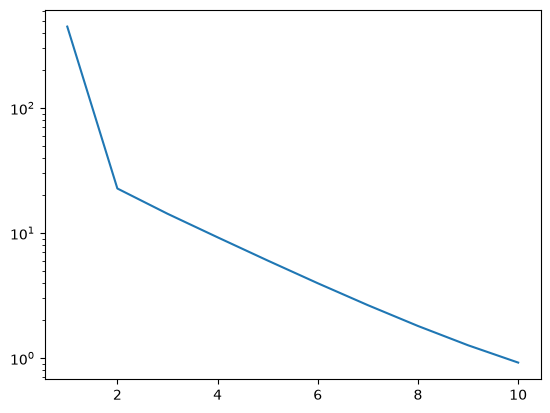

In [246]:
plt.plot(np.arange(1, epochs+1), loss_arr)
plt.yscale("log")